# Speculative decoding report — Qwen3-4B

Final tables and figures for the comparison in [`EXPERIMENTS.md`](../../EXPERIMENTS.md), computed from the
logs written by `python -m experiments.run_sweep` (record schemas: [`experiments/README.md`](../README.md)).

Edit **only the configuration cell** below, then *Run All*. Nothing else hardcodes run paths, `K` values,
datasets or methods.

| Section | Content |
|---|---|
| 1–2 | configuration, imports, plot style |
| 3–4 | log discovery / loading, validation and sanity checks |
| 5 | metric definitions and computation |
| 6 | **Table 1** — accepted length at `BASE_K` |
| 7 | **Figure 1** — position-wise conditional acceptance at `BASE_K` |
| 8 | **Figure 2** — accepted length and decode latency vs `K` |
| 9 | **Figure 3** — additional memory of the speculative machinery vs `K` |
| 10 | **Table 4** — GSM8K comparison with the EAGLE-3 paper (EAGLE-compatible τ) |
| 11 | supporting diagnostics |

## 1. Configuration

In [1]:
# ---- Configuration: the only cell that needs editing --------------------------------------------
# Logs. LOG_DIR is either one run directory (contains manifest.json) or a directory with run
# directories below it. Relative paths are resolved against the repository root.
LOG_DIR = "experiments/results"
RUNS = "latest"          # "latest" = newest run under LOG_DIR; "all" = merge every run; or a list of run ids

K_VALUES = [3, 5, 7]     # draft lengths to report (current logs); later e.g. [4, 8, 12, 16]
BASE_K = 7               # K used for the fixed-K comparisons (Table 1, Figure 1)

DATASETS = ["gsm8k", "math500", "aime25"]       # order of columns / panels; missing ones are skipped
METHODS = ["eagle3", "dflash", "dspark"]        # speculative methods, in display order
AR_METHOD = "ar"                                # autoregressive baseline (logged with k = 0)

FOCUS_METHOD = "dspark"                         # method whose relative improvement is reported
BASELINES = ["eagle3", "dflash"]                # ... relative to these (Table 1)
REF_METHOD = "dflash"                           # reference for the Figure 2 annotations

TABLE4_DATASET = "gsm8k"
TABLE4_SELECT_BY = "speedup"                    # pick the best K per method by "speedup" or "tau"

METHOD_NAMES = {"ar": "AR (Qwen3-4B)", "eagle3": "EAGLE-3", "dflash": "DFlash", "dspark": "DSpark"}
DATASET_NAMES = {"gsm8k": "GSM8K", "math500": "Math500", "aime25": "AIME25"}

OUTPUT_DIR = None        # None = "<LOG_DIR or the single run dir>/report"; False = do not save anything
SAVE_FORMATS = ("pdf", "png")

# ---- Values copied from external papers (NOT measured here) -------------------------------------
# DSpark paper, main table, Qwen3-4B target, math benchmarks: average accepted length incl. the bonus
# token, in the paper's own setting (its block size / sampling settings, not necessarily ours).
DSPARK_PAPER_TABLE1 = {
    "eagle3": {"gsm8k": 5.14, "math500": 4.62, "aime25": 3.92},
    "dflash": {"gsm8k": 5.40, "math500": 4.85, "aime25": 4.15},
    "dspark": {"gsm8k": 6.11, "math500": 5.70, "aime25": 4.89},
}
# EAGLE-3 paper (Li et al., 2025), GSM8K. Not in the repository: fill in from the paper, together
# with the target model and temperature the number refers to. None renders as "—".
EAGLE3_PAPER_GSM8K = {
    "target_model": None,
    "temperature": None,
    "acceptance_length": None,   # τ
    "speedup": None,
}

## 2. Imports and plotting style

In [2]:
import json
import warnings
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def find_repo_root(start: Path) -> Path:
    for path in [start, *start.parents]:
        if (path / "experiments").is_dir() and (path / "deepspec").is_dir():
            return path
    raise FileNotFoundError("repository root (with experiments/ and deepspec/) not found")


REPO_ROOT = find_repo_root(Path.cwd().resolve())


def resolve(path) -> Path:
    path = Path(path)
    return path if path.is_absolute() else REPO_ROOT / path


GIB = 1024 ** 3
PHASES = ["draft_ms", "verification_ms", "update_ms", "commit_ms"]
PHASE_NAMES = {"draft_ms": "draft", "verification_ms": "verification",
               "update_ms": "drafter update", "commit_ms": "commit / other"}

# Categorical palette in a fixed order (method identity follows the method, never its rank);
# markers are a second, non-color encoding. AR is a neutral reference, not a series.
_SERIES = ["#2a78d6", "#1baf7a", "#eb6834", "#eda100", "#e87ba4", "#6250d6", "#008300", "#e34948"]
_MARKERS = ["^", "o", "s", "D", "v", "P", "X", "h"]
AR_COLOR = "#77766f"
INK, MUTED, GRID = "#1f1e1b", "#6b6a64", "#e4e3dd"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
})
pd.set_option("display.precision", 3)

## 3. Log discovery and loading

A *run* is a directory with `manifest.json`, `samples.<method>.rank<r>.jsonl`, `steps.<method>.rank<r>.jsonl`,
`summary.jsonl` and `workers/<method>.rank<r>.json`. With `RUNS = "all"`, runs are merged; if the same
`(method, dataset, k)` appears in several runs, the newest run wins (reported below), and runs with different
generation settings are refused, because their numbers would not be comparable.

In [3]:
def read_jsonl(path: Path) -> list[dict]:
    with open(path, encoding="utf-8") as handle:
        return [json.loads(line) for line in handle if line.strip()]


def discover_runs(log_dir: Path) -> list[Path]:
    if (log_dir / "manifest.json").is_file():
        return [log_dir]
    return sorted(p.parent for p in log_dir.rglob("manifest.json"))


def load_run(run_dir: Path) -> dict:
    manifest = json.loads((run_dir / "manifest.json").read_text())
    run_id = manifest.get("run_id", run_dir.name)

    def frame(rows):
        df = pd.DataFrame(rows)
        if len(df):
            df.insert(0, "run_id", run_id)
        return df

    samples = frame([r for p in sorted(run_dir.glob("samples.*.jsonl")) for r in read_jsonl(p)])
    steps = frame([r for p in sorted(run_dir.glob("steps.*.jsonl")) for r in read_jsonl(p)])
    summary_path = run_dir / "summary.jsonl"
    summary = frame(read_jsonl(summary_path) if summary_path.is_file() else [])
    workers = frame([json.loads(p.read_text()) for p in sorted((run_dir / "workers").glob("*.json"))])
    return {"run_id": run_id, "dir": run_dir, "manifest": manifest, "samples": samples,
            "steps": steps, "summary": summary, "workers": workers}


def select_runs(log_dir: Path, runs) -> list[dict]:
    found = discover_runs(log_dir)
    if not found:
        raise FileNotFoundError(f"no run (manifest.json) under {log_dir}")
    loaded = sorted((load_run(d) for d in found), key=lambda r: r["manifest"].get("start_time", ""))
    if runs == "latest":
        return loaded[-1:]
    if runs == "all":
        return loaded
    by_id = {r["run_id"]: r for r in loaded}
    missing = [r for r in runs if r not in by_id]
    if missing:
        raise KeyError(f"runs not found under {log_dir}: {missing}; available: {list(by_id)}")
    return [by_id[r] for r in runs]


GROUP = ["method", "dataset", "k"]
SAMPLE_KEY = GROUP + ["sample_idx"]


def merge_runs(runs: list[dict]) -> dict:
    """Concatenates runs; for a (method, dataset, k) present in several runs, keeps the newest."""
    gens = {r["run_id"]: r["manifest"]["config"].get("generation") for r in runs}
    if len({json.dumps(g, sort_keys=True) for g in gens.values()}) > 1:
        raise ValueError(f"runs use different generation settings, not comparable: {gens}")
    owner = {}  # (method, dataset, k) -> run_id of the newest run that has it
    for r in runs:  # sorted oldest -> newest
        if len(r["samples"]):
            for key in r["samples"][GROUP].drop_duplicates().itertuples(index=False):
                if key in owner:
                    warnings.warn(f"{tuple(key)} in runs {owner[key]} and {r['run_id']}; using {r['run_id']}")
                owner[tuple(key)] = r["run_id"]
    keep = pd.DataFrame([(*k, v) for k, v in owner.items()], columns=GROUP + ["run_id"])

    def cat(name, on=GROUP + ["run_id"]):
        df = pd.concat([r[name] for r in runs if len(r[name])], ignore_index=True)
        return df.merge(keep, on=on) if len(df) else df

    workers = pd.concat([r["workers"] for r in runs if len(r["workers"])], ignore_index=True)
    workers = workers.merge(keep[["method", "run_id"]].drop_duplicates(), on=["method", "run_id"])
    return {"runs": runs, "samples": cat("samples"), "steps": cat("steps"), "summary": cat("summary"),
            "workers": workers, "generation": next(iter(gens.values()))}


LOG_PATH = resolve(LOG_DIR)
data = merge_runs(select_runs(LOG_PATH, RUNS))
samples, steps, summary, workers = data["samples"], data["steps"], data["summary"], data["workers"]

if OUTPUT_DIR is False:
    OUT_DIR = None
else:
    OUT_DIR = resolve(OUTPUT_DIR) if OUTPUT_DIR else (
        data["runs"][0]["dir"] if len(data["runs"]) == 1 else LOG_PATH) / "report"
    OUT_DIR.mkdir(parents=True, exist_ok=True)

run_table = pd.DataFrame([{
    "run_id": r["run_id"], "git commit": r["manifest"].get("git", {}).get("commit", "")[:9],
    "dirty": r["manifest"].get("git", {}).get("dirty"),
    "methods": ", ".join(sorted(r["samples"]["method"].unique())) if len(r["samples"]) else "",
    "K in logs": sorted(int(k) for k in r["samples"]["k"].unique()) if len(r["samples"]) else [],
    "GPU": ", ".join(r["workers"]["gpu_name"].unique()) if len(r["workers"]) else "",
} for r in data["runs"]])
display(run_table)
display(Markdown(f"Generation settings: `{data['generation']}` · samples: {len(samples):,} · "
                 f"steps: {len(steps):,} · outputs: `{OUT_DIR}`"))

,run_id,git commit,dirty,methods,K in logs,GPU
0,20261025T162558Z_qwen3_4b_smoke,c1e39a5df,True,"ar, dflash, dspark, eagle3","[0, 3, 5, 7]",NVIDIA GeForce RTX 3090


Generation settings: `{'temperature': 1.0, 'max_new_tokens': 128, 'seed': 980406, 'enable_thinking': False}` · samples: 150 · steps: 6,371 · outputs: `/media/atem/Data/HSE_videos/PROJECTS/DeepSpec/experiments/results/20261025T162558Z_qwen3_4b_smoke/report`

## 4. Validation and sanity checks

Coverage of the requested matrix, and the record invariants documented in `experiments/README.md`, recomputed
from the stored records. A failed check does not stop the notebook, but the affected numbers should not be
reported before the cause is understood.

In [4]:
checks = []


def check(name, ok, detail=""):
    checks.append({"check": name, "status": "ok" if ok else "FAIL", "detail": str(detail)[:200]})
    if not ok:
        warnings.warn(f"{name}: {detail}")


# ---- Requested matrix -----------------------------------------------------------------------------
present = set(map(tuple, samples[GROUP].drop_duplicates().itertuples(index=False)))
logged_k = sorted({k for m, _, k in present if m != AR_METHOD})
check("BASE_K is in K_VALUES", BASE_K in K_VALUES, f"BASE_K={BASE_K}, K_VALUES={K_VALUES}")
check("K_VALUES are present in the logs", set(K_VALUES) <= set(logged_k),
      f"requested {K_VALUES}, logged {logged_k}")
missing = [(m, d, k) for m in METHODS for d in DATASETS for k in K_VALUES if (m, d, k) not in present]
missing += [(AR_METHOD, d, 0) for d in DATASETS if (AR_METHOD, d, 0) not in present]
check("all requested (method, dataset, K) combinations present", not missing, missing)
extra_methods = sorted({m for m, _, _ in present} - set(METHODS) - {AR_METHOD})
if extra_methods:
    print(f"note: methods in the logs but not in METHODS (ignored): {extra_methods}")
if sorted(set(logged_k) - set(K_VALUES)):
    print(f"note: K values in the logs but not in K_VALUES (ignored): {sorted(set(logged_k) - set(K_VALUES))}")

# Restrict everything below to the configured matrix.
in_scope = lambda df: df[(df["dataset"].isin(DATASETS)) & (
    ((df["method"] == AR_METHOD) & (df["k"] == 0)) | (df["method"].isin(METHODS) & df["k"].isin(K_VALUES)))]
samples, steps = in_scope(samples).copy(), in_scope(steps).copy()
DS = [d for d in DATASETS if d in set(samples["dataset"])]
MS = [m for m in METHODS if m in set(samples["method"])]
KS = sorted(k for k in K_VALUES if k in set(samples.loc[samples["method"] != AR_METHOD, "k"]))
HAS_AR = AR_METHOD in set(samples["method"])

# ---- Record invariants --------------------------------------------------------------------------
agg = steps.groupby(SAMPLE_KEY).agg(n=("step", "size"), committed=("committed", "sum"),
                                     **{p: (p, "sum") for p in PHASES})
s = samples.set_index(SAMPLE_KEY).join(agg[["n", "committed"]])
s["n"] = s["n"].fillna(0)
check("one step record per speculative step", (s["n"] == s["num_steps"]).all(),
      s.index[s["n"] != s["num_steps"]].tolist()[:5])
stop = s["stop_reason"] == "stop_token"
tot = 1 + s["committed"].fillna(0)
ok = np.where(stop, tot == s["generated_len"], tot >= s["generated_len"])
check("1 + Σ committed == generated_len (≥ when length-limited)", ok.all(), s.index[~ok].tolist()[:5])
STEP_TIMING = samples["draft_ms"].notna().all()
check("per-step timing recorded (step_timing=true)", STEP_TIMING,
      "phase latencies are null; latency figures will be empty")
if STEP_TIMING:
    diff = max(float((s[p] - agg[p].reindex(s.index).fillna(0)).abs().max()) for p in PHASES)
    check("sample phase sums == Σ step phases", diff < 1e-3, f"max |diff| = {diff:.2e} ms")
st = steps
check("0 ≤ accepted ≤ effective_len ≤ drafted_len",
      ((st["accepted"] >= 0) & (st["accepted"] <= st["effective_len"]) & (st["effective_len"] <= st["drafted_len"])).all())
check("committed ∈ {accepted, accepted + 1}", (st["committed"] - st["accepted"]).isin([0, 1]).all())
check("requested_len == K", (st["requested_len"] == st["k"]).all())
check("drafted_len ≤ K", (st["drafted_len"] <= st["k"]).all())

# ---- Comparability across methods ----------------------------------------------------------------
sha = samples.groupby(["dataset", "sample_idx"])["prompt_sha1"].nunique()
check("same prompt for a sample_idx across methods / K", (sha == 1).all(), sha[sha > 1].index.tolist()[:5])
sets = samples.groupby(GROUP)["sample_idx"].apply(frozenset)
same = sets.groupby(level="dataset").apply(lambda x: x.nunique() == 1)
check("same sample set for every (method, K) within a dataset", same.all(), same[~same].index.tolist())

# ---- Summary parity (summary.jsonl was written online; recompute from the step records) ----------
if len(summary):
    g = steps.groupby(GROUP).agg(n=("step", "size"), committed=("committed", "sum"), accepted=("accepted", "sum"))
    worst = 0.0
    for row in summary.itertuples():
        key = (row.method, row.dataset, row.k)
        if key not in g.index:
            continue
        native = g.loc[key, "committed"] / g.loc[key, "n"]
        ds_block = row.deepspec_metrics if isinstance(getattr(row, "deepspec_metrics", None), dict) else row.metrics
        worst = max(worst, abs(native - ds_block["acceptance_length"]))
    check("summary.jsonl acceptance_length == Σ committed / Σ steps", worst < 1e-9, f"max |diff| = {worst:.2e}")

# ---- Informational -------------------------------------------------------------------------------
lim = samples.groupby(GROUP)["stop_reason"].apply(lambda x: (x == "length").mean())
check("share of length-limited samples ≤ 50% (outputs not dominated by truncation)", (lim <= 0.5).all(),
      f"max share {lim.max():.0%} at {lim.idxmax()}; max_new_tokens={data['generation'].get('max_new_tokens')}")
n_per = samples.groupby(GROUP).size()
check("≥ 30 samples per (method, dataset, K)", (n_per >= 30).all(), f"min {n_per.min()} samples")

display(pd.DataFrame(checks).style.apply(
    lambda c: ["color: #c0392b; font-weight: bold" if v == "FAIL" else "" for v in c], subset=["status"]))

/tmp/ipykernel_20402/4030452477.py:7: UserWarning: share of length-limited samples ≤ 50% (outputs not dominated by truncation): max share 100% at ('ar', 'aime25', np.int64(0)); max_new_tokens=128
  warnings.warn(f"{name}: {detail}")
/tmp/ipykernel_20402/4030452477.py:7: UserWarning: ≥ 30 samples per (method, dataset, K): min 5 samples
  warnings.warn(f"{name}: {detail}")


,check,status,detail
0,BASE_K is in K_VALUES,ok,"BASE_K=7, K_VALUES=[3, 5, 7]"
1,K_VALUES are present in the logs,ok,"requested [3, 5, 7], logged [3, 5, 7]"
2,"all requested (method, dataset, K) combinations present",ok,[]
3,one step record per speculative step,ok,[]
4,1 + Σ committed == generated_len (≥ when length-limited),ok,[]
5,per-step timing recorded (step_timing=true),ok,phase latencies are null; latency figures will be empty
6,sample phase sums == Σ step phases,ok,max |diff| = 0.00e+00 ms
7,0 ≤ accepted ≤ effective_len ≤ drafted_len,ok,
8,"committed ∈ {accepted, accepted + 1}",ok,
9,requested_len == K,ok,


## 5. Metric definitions

Field semantics, verified in `deepspec/eval/base_evaluator.py` (`verify_draft_tokens`, `generate_decoding_sample`),
`experiments/instrumentation.py`, `experiments/records.py` and `experiments/metrics.py`:

| Field | Meaning |
|---|---|
| `requested_len` | `K` (0 for AR) |
| `drafted_len` | tokens the drafter produced; `< K` only when the EAGLE-3 chain samples a stop token |
| `effective_len` | draft tokens verified (DeepSpec's `proposal_lengths`): `drafted_len`, truncated after an *accepted* stop token |
| `accepted` | length of the accepted draft prefix (rejection sampling, `cumprod` of per-position accepts) — **excludes** the bonus token |
| `committed` | tokens appended this step: `accepted + 1` (bonus / corrected target token), or `accepted` when an accepted draft token is a stop token |
| `generated_len`, `num_steps` | output tokens incl. the first token sampled at prefill (trimmed to `max_new_tokens`); number of verifications |
| `draft_ms` / `verification_ms` / `update_ms` / `commit_ms` | GPU-stream CUDA-event intervals of `propose` / target forward + acceptance / drafter state update / the rest of the step (KV crop, bookkeeping); they tile the decode timeline |
| `target_prefill_ms`, `init_context_ms` | prompt forward + first token; drafter initialisation from the prompt — both **excluded** from decode latency |
| `wall_ms` | host clock over the whole sample (prefill included); a cross-check only |
| `prefill_peak_bytes`, `decode_peak_bytes` | `max_memory_allocated()` (absolute, weights included) during prefill + `init_context`, and during decode (stats reset in between) |
| summary `deepspec_metrics.acceptance_length` | DeepSpec's: Σ `committed` / Σ steps — **includes** the bonus token |
| summary `metrics.acceptance_length` | ours: Σ `accepted` / Σ steps — excludes the bonus token |
| `accept_rates_by_position[i]` | steps with `accepted > i` / steps with `effective_len > i`: prefix **survival**, not conditional acceptance |

Metrics used in the report (all ratio-of-sums over every step / sample of a `(method, dataset, K)` group, so long
generations weigh by their number of steps / tokens rather than one vote per sample):

| Metric | Definition | Used in |
|---|---|---|
| **accepted length** `A` | Σ `committed` / Σ steps — DeepSpec's native `acceptance_length`, bonus token included | Table 1, Figure 2a |
| acceptance rate | Σ `committed` / (Σ `effective_len` + Σ steps) — DeepSpec's `verify_rate`, bonus included | diagnostics |
| draft acceptance rate | Σ `accepted` / Σ `effective_len` (bonus excluded, labelled as such) | diagnostics |
| conditional acceptance at position `i` | #steps with `accepted ≥ i` / #steps with `accepted ≥ i−1` and `effective_len ≥ i` | Figure 1 |
| decode latency per token | Σ (`draft`+`verification`+`update`+`commit`) / Σ (`generated_len` − 1) | Figure 2b, Table 4 |
| decode latency per round | same numerator / Σ steps | Figure 2b |
| speedup | AR decode ms/token ÷ method decode ms/token (same dataset, same prompts) | Table 4, diagnostics |
| **EAGLE-compatible τ** | Σ `generated_len` / Σ `num_steps` — **Table 4 only** | Table 4 |

The decode-token denominator `generated_len − 1` excludes the token sampled at prefill (its cost is in
`target_prefill_ms`) and counts only tokens kept in the output: tokens committed past `max_new_tokens` and then
trimmed are work without output, as in a real deployment.

In [5]:
def safe_div(a, b):
    return np.where(np.asarray(b) > 0, np.asarray(a, dtype=float) / np.where(np.asarray(b) > 0, b, 1), np.nan)


samples["decode_ms"] = samples[PHASES].sum(axis=1, min_count=len(PHASES))
samples["decode_tokens"] = (samples["generated_len"] - 1).clip(lower=0)
samples["peak_bytes"] = samples[["prefill_peak_bytes", "decode_peak_bytes"]].max(axis=1)
samples["context_len"] = samples["prompt_len"] + samples["generated_len"]


def group_metrics(samples: pd.DataFrame, steps: pd.DataFrame) -> pd.DataFrame:
    st = steps.groupby(GROUP).agg(steps=("step", "size"), committed=("committed", "sum"),
                                  accepted=("accepted", "sum"), effective=("effective_len", "sum"),
                                  drafted=("drafted_len", "sum"))
    sa = samples.groupby(GROUP).agg(
        n_samples=("sample_idx", "size"), num_steps=("num_steps", "sum"), generated=("generated_len", "sum"),
        decode_tokens=("decode_tokens", "sum"), decode_ms=("decode_ms", "sum"),
        **{p: (p, "sum") for p in PHASES},
        prefill_ms=("target_prefill_ms", "mean"), init_context_ms=("init_context_ms", "mean"),
        prompt_len=("prompt_len", "mean"), generated_len=("generated_len", "mean"),
        length_limited=("stop_reason", lambda x: (x == "length").mean()),
        peak_gib=("peak_bytes", lambda x: x.mean() / GIB), peak_max_gib=("peak_bytes", lambda x: x.max() / GIB))
    g = sa.join(st, how="left")
    g["accept_len"] = safe_div(g["committed"], g["steps"])            # native, bonus included
    g["accepted_draft_per_step"] = safe_div(g["accepted"], g["steps"])  # bonus excluded
    g["eff_draft_len"] = safe_div(g["effective"], g["steps"])
    g["acceptance_rate"] = safe_div(g["committed"], g["effective"] + g["steps"])
    g["draft_acceptance_rate"] = safe_div(g["accepted"], g["effective"])
    g["tau_eagle"] = safe_div(g["generated"], g["num_steps"])          # Table 4 only
    g["ms_per_token"] = safe_div(g["decode_ms"], g["decode_tokens"])
    g["ms_per_round"] = safe_div(g["decode_ms"], g["steps"])
    for p in PHASES:
        g[p + "_per_round"] = safe_div(g[p], g["steps"])
        g[p + "_per_token"] = safe_div(g[p], g["decode_tokens"])
    g["tokens_per_s"] = 1e3 / g["ms_per_token"]
    g = g.reset_index()
    if HAS_AR:
        ar = g[g["method"] == AR_METHOD].set_index("dataset")["ms_per_token"]
        g["speedup"] = g["dataset"].map(ar) / g["ms_per_token"]
    else:
        g["speedup"] = np.nan
    return g


G = group_metrics(samples, steps)


def metric(method, dataset, k, col):
    row = G[(G["method"] == method) & (G["dataset"] == dataset) & (G["k"] == k)]
    return float(row[col].iloc[0]) if len(row) else np.nan


def rel(a, b):
    return 100.0 * (a - b) / b


def name(m):
    return METHOD_NAMES.get(m, m)


def dname(d):
    return DATASET_NAMES.get(d, d)


STYLE = {m: {"color": _SERIES[i % len(_SERIES)], "marker": _MARKERS[i % len(_MARKERS)]}
         for i, m in enumerate(METHODS)}
STYLE[AR_METHOD] = {"color": AR_COLOR, "marker": "x"}


def save(fig, stem):
    if OUT_DIR is not None:
        for fmt in SAVE_FORMATS:
            fig.savefig(OUT_DIR / f"{stem}.{fmt}")


def save_table(df, stem):
    if OUT_DIR is not None:
        df.to_csv(OUT_DIR / f"{stem}.csv")


def legend_below(fig, methods, ar=False, extra=()):
    handles = [plt.Line2D([], [], color=STYLE[m]["color"], marker=STYLE[m]["marker"], label=name(m)) for m in methods]
    if ar:
        handles.append(plt.Line2D([], [], color=AR_COLOR, ls="--", label=name(AR_METHOD)))
    handles += list(extra)
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.02))


cols = ["method", "dataset", "k", "n_samples", "steps", "accept_len", "eff_draft_len", "ms_per_token",
        "ms_per_round", "speedup", "generated_len", "length_limited"]
display(G[cols].sort_values(["dataset", "method", "k"]).reset_index(drop=True))

,method,dataset,k,n_samples,steps,accept_len,eff_draft_len,ms_per_token,ms_per_round,speedup,generated_len,length_limited
0,ar,aime25,0,5,640,1.000,0.000,56.883,56.438,1.000,128.0,1.0
1,dflash,aime25,3,5,226,2.850,3.000,26.936,75.683,2.112,128.0,1.0
2,dflash,aime25,5,5,160,4.044,5.000,19.191,76.162,2.964,128.0,1.0
3,dflash,aime25,7,5,133,4.940,7.000,15.983,76.311,3.559,128.0,1.0
4,dspark,aime25,3,5,187,3.449,3.000,21.942,74.507,2.592,128.0,1.0
5,dspark,aime25,5,5,131,4.947,5.000,15.609,75.662,3.644,128.0,1.0
6,dspark,aime25,7,5,110,5.882,7.000,13.321,76.899,4.270,128.0,1.0
7,eagle3,aime25,3,5,205,3.161,3.000,24.854,76.987,2.289,128.0,1.0
8,eagle3,aime25,5,5,168,3.851,5.000,22.269,84.172,2.554,128.0,1.0
9,eagle3,aime25,7,5,170,3.806,7.000,24.458,91.359,2.326,128.0,1.0


## 6. Table 1 — Main speculative decoding results (`K = BASE_K`)

Average accepted length per decoding round, **A = Σ committed / Σ rounds** (DeepSpec's native
`acceptance_length`; the target-generated bonus / corrected token is included, so `A ≤ K + 1`). Higher is better;
the best value per column is bold. Macro average = unweighted mean over datasets (only when all datasets are
present for that method).

Relative improvement of the focus method: (A<sub>focus</sub> − A<sub>baseline</sub>) / A<sub>baseline</sub> × 100%;
its macro average is the mean of the per-dataset relative improvements.

In [6]:
def table1(k: int) -> pd.DataFrame:
    t = pd.DataFrame({dname(d): [metric(m, d, k, "accept_len") for m in MS] for d in DS},
                     index=[name(m) for m in MS])
    t.index.name = f"Drafter (K={k})"
    t["Macro avg"] = t.mean(axis=1, skipna=False) if len(DS) > 1 else np.nan
    return t


def bold_max(col):
    return ["font-weight: bold" if np.isfinite(v) and v == np.nanmax(col) else "" for v in col]


T1 = table1(BASE_K)
display(Markdown(f"**Table 1.** Average accepted length (incl. bonus token), Qwen3-4B target, K = {BASE_K}."))
display(T1.style.apply(bold_max).format("{:.2f}", na_rep="—"))
save_table(T1, f"table1_accept_len_K{BASE_K}")

if FOCUS_METHOD in MS:
    rows = {}
    for b in [b for b in BASELINES if b in MS and b != FOCUS_METHOD]:
        r = {dname(d): rel(metric(FOCUS_METHOD, d, BASE_K, "accept_len"), metric(b, d, BASE_K, "accept_len"))
             for d in DS}
        r["Macro avg"] = np.mean(list(r.values())) if len(DS) > 1 else np.nan
        rows[f"{name(FOCUS_METHOD)} vs {name(b)}"] = r
    T1_rel = pd.DataFrame(rows).T
    display(Markdown(f"Relative improvement of {name(FOCUS_METHOD)} in accepted length, %:"))
    display(T1_rel.style.format("{:+.1f}%", na_rep="—"))
    save_table(T1_rel, f"table1_rel_improvement_K{BASE_K}")

paper = pd.DataFrame({dname(d): [DSPARK_PAPER_TABLE1.get(m, {}).get(d, np.nan) for m in MS] for d in DS},
                     index=[name(m) for m in MS])
if paper.notna().any().any():
    display(Markdown("Reference only — **values copied from the DSpark paper** (its own setting), and our "
                     f"measurement at K = {BASE_K} relative to them:"))
    display(pd.concat({"paper": paper, "ours / paper": T1[paper.columns] / paper}, axis=1)
            .style.format("{:.2f}", na_rep="—"))

**Table 1.** Average accepted length (incl. bonus token), Qwen3-4B target, K = 7.

,GSM8K,Math500,AIME25,Macro avg
Drafter (K=7),,,,
EAGLE-3,4.35,4.19,3.81,4.11
DFlash,5.17,4.40,4.94,4.84
DSpark,5.90,5.38,5.88,5.72


Relative improvement of DSpark in accepted length, %:

,GSM8K,Math500,AIME25,Macro avg
DSpark vs EAGLE-3,+35.8%,+28.4%,+54.5%,+39.6%
DSpark vs DFlash,+14.2%,+22.3%,+19.1%,+18.5%


Reference only — **values copied from the DSpark paper** (its own setting), and our measurement at K = 7 relative to them:

## 7. Figure 1 — Position-wise conditional acceptance (`K = BASE_K`)

For draft position `i = 1 … K`:

$$P(\text{position } i \text{ accepted} \mid \text{positions } 1,\dots,i-1 \text{ accepted})
= \frac{\#\{\text{rounds}: \text{accepted} \ge i\}}{\#\{\text{rounds}: \text{accepted} \ge i-1,\ \text{effective\_len} \ge i\}}.$$

**Exactly reconstructable from the step logs.** Verification accepts a *prefix*
(`accept_prefix_mask = cumprod(accept_mask)`), so "positions 1…i−1 accepted" ⇔ `accepted ≥ i−1`, and position `i`
was actually verified iff `effective_len ≥ i`. Rounds whose draft ended earlier (EAGLE-3 chain stopped at a stop
token; truncation after an accepted stop token) are excluded from the denominator at the positions they did not
verify. The per-round accept mask beyond the first rejection is not logged, but it is not needed: those positions
are by definition not in the conditional's denominator.

This differs from DeepSpec's `accept_rates_by_position` (prefix *survival* `P(accepted ≥ i)`, which decays
multiplicatively by construction); the two are compared in §11. Shaded bands are 95% Wilson intervals over rounds
(rounds within a sample are not independent, so the bands are optimistic). The number of rounds reaching the last
positions is printed below the figure.

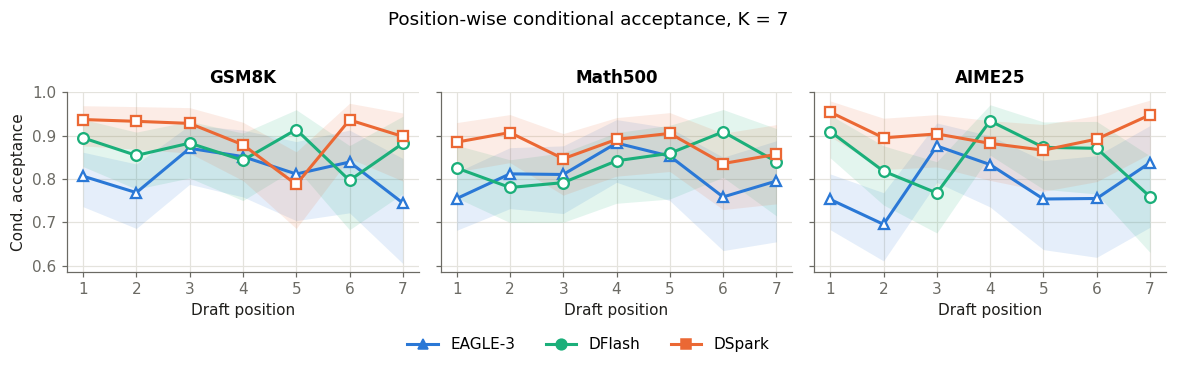

Rounds in the denominator (`reached`) per position:

position           1    2   3   4   5   6   7
GSM8K   EAGLE-3  150  121  93  81  69  56  47
        DFlash   124  110  94  83  70  64  51
        DSpark   112  105  98  91  80  63  59
Math500 EAGLE-3  155  117  95  77  68  58  44
        DFlash   149  123  96  76  64  55  50
        DSpark   122  108  98  83  74  67  56
AIME25  EAGLE-3  170  128  89  78  65  49  37
        DFlash   133  121  99  76  71  62  54
        DSpark   110  105  94  85  75  65  58

In [7]:
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    with np.errstate(invalid="ignore", divide="ignore"):
        p = k / n
        d = 1 + z * z / n
        c = (p + z * z / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def position_acceptance(st: pd.DataFrame, k: int) -> pd.DataFrame:
    acc, eff = st["accepted"].to_numpy()[:, None], st["effective_len"].to_numpy()[:, None]
    pos = np.arange(1, k + 1)[None, :]
    num = (acc >= pos).sum(0)
    den = ((acc >= pos - 1) & (eff >= pos)).sum(0)
    surv_den = (eff >= pos).sum(0)
    lo, hi = wilson(num, den)
    return pd.DataFrame({"position": pos[0], "accepted": num, "reached": den,
                         "conditional": safe_div(num, den), "lo": lo, "hi": hi,
                         "survival": safe_div(num, surv_den)})


POS = {(m, d, k): position_acceptance(steps[(steps["method"] == m) & (steps["dataset"] == d) & (steps["k"] == k)], k)
       for m in MS for d in DS for k in KS}


def plot_conditional(k: int):
    fig, axes = plt.subplots(1, len(DS), figsize=(3.6 * len(DS), 3.1), sharey=True, squeeze=False)
    for ax, d in zip(axes[0], DS):
        for m in MS:
            p = POS.get((m, d, k))
            if p is None or p["reached"].sum() == 0:
                continue
            ax.fill_between(p["position"], p["lo"], p["hi"], color=STYLE[m]["color"], alpha=0.12, lw=0)
            ax.plot(p["position"], p["conditional"], **STYLE[m], markerfacecolor="white", markeredgewidth=1.5)
        ax.set_title(dname(d))
        ax.set_xticks(range(1, k + 1))
        ax.set_xlabel("Draft position")
    axes[0, 0].set_ylabel("Cond. acceptance")
    legend_below(fig, MS)
    fig.suptitle(f"Position-wise conditional acceptance, K = {k}", y=1.02)
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    return fig


if BASE_K in KS:
    fig = plot_conditional(BASE_K)
    save(fig, f"fig1_conditional_acceptance_K{BASE_K}")
    plt.show()
    support = pd.DataFrame({(dname(d), name(m)): POS[(m, d, BASE_K)].set_index("position")["reached"]
                            for d in DS for m in MS}).T
    display(Markdown("Rounds in the denominator (`reached`) per position:"))
    display(support)
    save_table(pd.concat({f"{m}|{d}": POS[(m, d, BASE_K)] for d in DS for m in MS}),
               f"fig1_conditional_acceptance_K{BASE_K}")
else:
    print(f"BASE_K={BASE_K} not in the logged K values {KS}")

## 8. Figure 2 — Effect of proposal length

### Figure 2a — Accepted length vs `K`

Native accepted length `A` (Σ committed / Σ rounds, bonus included) for every `K` in `K_VALUES`. The dotted line
`A = K + 1` is the ceiling (all drafts accepted). Annotations: relative gain of the focus method over
`REF_METHOD`, (A<sub>focus</sub> − A<sub>ref</sub>) / A<sub>ref</sub>, to show whether the gap grows with `K`.
Note that DFlash / DSpark checkpoints were trained with block 7: `K < 7` runs them off their training block size,
and `K > 7` would draft beyond it.

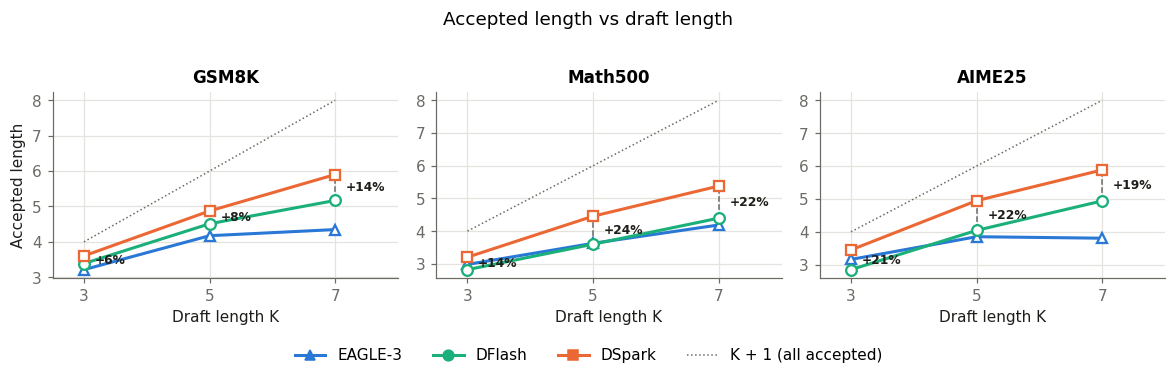

In [8]:
def annotate_gap(ax, k, y_top, y_ref, pct, fmt):
    # Dashed connector behind the markers (lines and markers are drawn at zorder 2).
    ax.plot([k, k], [y_ref, y_top], ls="--", color=MUTED, lw=1, zorder=1.5)
    ax.annotate(fmt.format(pct), xy=(k, (y_top + y_ref) / 2), xytext=(7, 0), textcoords="offset points",
                fontsize=8, color=INK, va="center", fontweight="bold")


def plot_vs_k(col, ylabel, title, *, ar_line=False, ceiling=False, annotate=None, ylim0=False, fname=None):
    fig, axes = plt.subplots(1, len(DS), figsize=(3.6 * len(DS), 3.2), squeeze=False)
    for ax, d in zip(axes[0], DS):
        for m in MS:
            ys = [metric(m, d, k, col) for k in KS]
            ax.plot(KS, ys, **STYLE[m], markerfacecolor="white", markeredgewidth=1.5)
        if ceiling:
            ax.plot(KS, [k + 1 for k in KS], ls=":", color=MUTED, lw=1)
        if ar_line and HAS_AR:
            ax.axhline(metric(AR_METHOD, d, 0, col), color=AR_COLOR, ls="--", lw=1.2)
        if ylim0:
            ax.set_ylim(bottom=0)
        ax.set_xlim(min(KS) - 0.5, max(KS) + 1.0)  # room for the labels right of the last K
        if annotate and FOCUS_METHOD in MS and REF_METHOD in MS:
            for k in KS:
                a, b = metric(FOCUS_METHOD, d, k, col), metric(REF_METHOD, d, k, col)
                if np.isfinite(a) and np.isfinite(b):
                    annotate_gap(ax, k, a, b, rel(a, b), annotate)
        ax.set_title(dname(d))
        ax.set_xticks(KS)
        ax.set_xlabel("Draft length K")
    axes[0, 0].set_ylabel(ylabel)
    extra = [plt.Line2D([], [], color=MUTED, ls=":", lw=1, label="K + 1 (all accepted)")] if ceiling else []
    legend_below(fig, MS, ar=ar_line and HAS_AR, extra=extra)
    fig.suptitle(title, y=1.02)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    if fname:
        save(fig, fname)
    plt.show()


plot_vs_k("accept_len", "Accepted length", "Accepted length vs draft length",
          ceiling=True, annotate="{:+.0f}%", fname="fig2a_accept_len_vs_k")

### Figure 2b — Decode latency vs `K`

Latency on our benchmark prompts with their natural context lengths (no controlled averaging over fixed context
lengths as in the DSpark paper). Decode = `draft + verification + update + commit` — target prefill and
`init_context` are excluded (§11 reports them separately).

* **per round** = decode ms / Σ rounds: cost of one draft + verify iteration — the analogue of the paper's latency
  figure; it grows with `K` because the drafter produces and the target verifies more tokens per round.
  Annotated with the focus method's overhead over `REF_METHOD`.
* **per token** = decode ms / Σ (generated_len − 1): what the user sees; combines the round cost with accepted
  length. The dashed line is the AR baseline.

Caveat: at temperature > 0 each method generates its own continuation, so context lengths (and thus per-round
target cost) differ somewhat between methods; compare `generated_len` in §11.

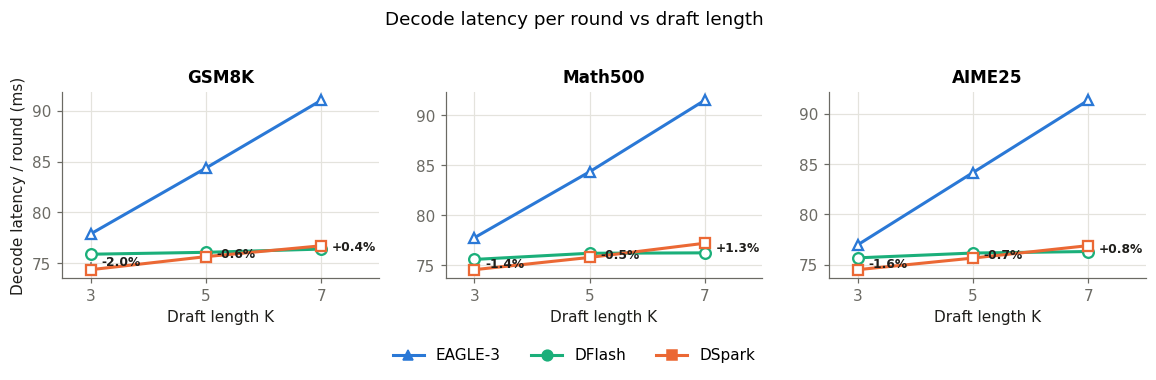

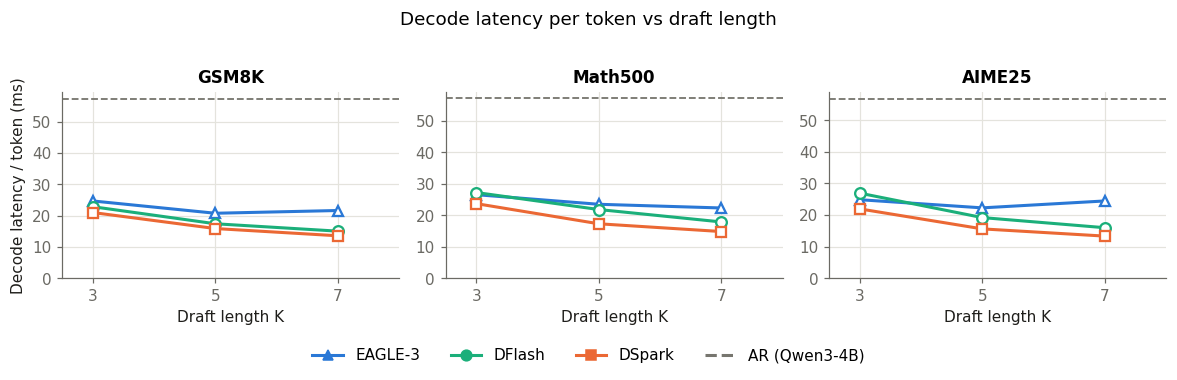

**Supporting table for Figure 2.** Δ columns are relative to DFlash at the same K.

In [9]:
if STEP_TIMING:
    plot_vs_k("ms_per_round", "Decode latency / round (ms)", "Decode latency per round vs draft length",
              annotate="{:+.1f}%", fname="fig2b_latency_per_round_vs_k")
    plot_vs_k("ms_per_token", "Decode latency / token (ms)", "Decode latency per token vs draft length",
              ar_line=True, ylim0=True, fname="fig2b_latency_per_token_vs_k")

rows = []
for d in DS:
    for m in MS:
        for k in KS:
            a, b = metric(m, d, k, "accept_len"), metric(REF_METHOD, d, k, "accept_len")
            lr, lr_ref = metric(m, d, k, "ms_per_round"), metric(REF_METHOD, d, k, "ms_per_round")
            lt, lt_ref = metric(m, d, k, "ms_per_token"), metric(REF_METHOD, d, k, "ms_per_token")
            rows.append({"dataset": dname(d), "method": name(m), "K": k, "accept. len": a,
                         "ms / round": lr, "ms / token": lt, "speedup vs AR": metric(m, d, k, "speedup"),
                         f"Δ accept. len vs {name(REF_METHOD)}": rel(a, b),
                         f"Δ ms/round vs {name(REF_METHOD)}": rel(lr, lr_ref),
                         f"Δ ms/token vs {name(REF_METHOD)}": rel(lt, lt_ref)})
T2 = pd.DataFrame(rows).set_index(["dataset", "method", "K"])
display(Markdown(f"**Supporting table for Figure 2.** Δ columns are relative to {name(REF_METHOD)} at the same K."))
display(T2.style.format({c: ("{:+.1f}%" if c.startswith("Δ") else "{:.2f}") for c in T2.columns}, na_rep="—"))
save_table(T2, "table_fig2_support")

## 9. Figure 3 — Additional memory of the speculative machinery

**Definition.** The logs record absolute `max_memory_allocated()` (weights included) per sample, separately for
prefill + `init_context` and for decode. Per sample, `peak = max(prefill_peak, decode_peak)`. The additional memory
of a method is the **paired** difference to the AR baseline on the same prompt (`dataset`, `sample_idx`; identical
`prompt_sha1`):

$$\Delta M = \operatorname{mean}_{\text{samples}}\big(\text{peak}_{\text{method}} - \text{peak}_{\text{AR}}\big).$$

Both runs share the target weights, the target KV cache and the target activations, so the difference isolates what
speculative decoding adds. It is split into

* **drafter weights** — `post_load_allocated_bytes` (method) − (AR), from `workers/*.json`: the drafter's parameters
  as actually allocated (including its own embedding / LM-head copies);
* **runtime** — the rest: drafter KV cache / context features, drafter activations, and the wider (K+1-token)
  target verification forward (logits, probabilities, hidden states).

Why not `decode_peak − prefill_peak`: both are absolute peaks of different phases; their difference mixes the
target KV growth during generation with the drafter and says nothing about drafter weights, which are resident in
both. Caveat: at temperature > 0 a method's output length differs from AR's on the same prompt, so the target KV
cache differs too; the mean context-length difference is reported with the bars (≈ 0.14 MiB of bf16 KV per token for
Qwen3-4B, before `DynamicCache` growth overheads).

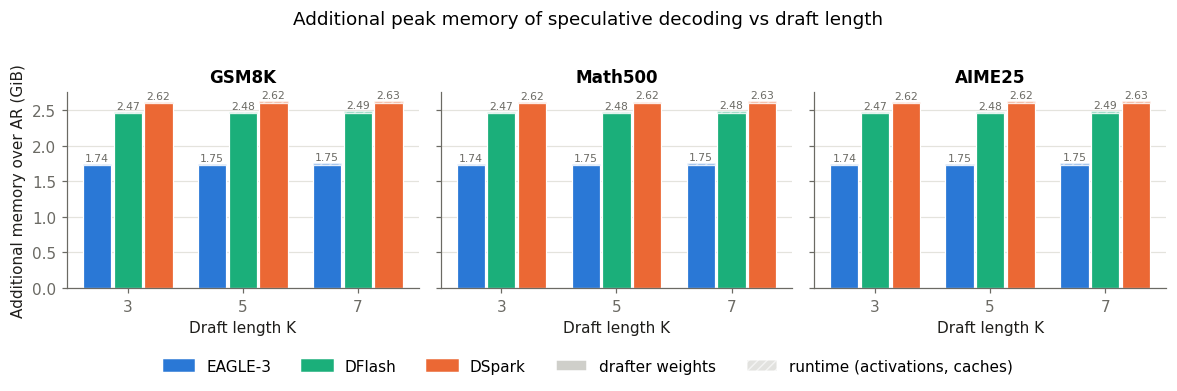

In [10]:
def memory_overhead() -> pd.DataFrame:
    if not HAS_AR:
        return pd.DataFrame()
    key = ["dataset", "sample_idx"]
    ar = samples[samples["method"] == AR_METHOD].set_index(key)[["peak_bytes", "context_len"]]
    post = workers.groupby("method")["post_load_allocated_bytes"].max() if len(workers) else pd.Series(dtype=float)
    rows = []
    for (m, d, k), grp in samples[samples["method"].isin(MS)].groupby(GROUP):
        j = grp.set_index(key)[["peak_bytes", "context_len"]].join(ar, rsuffix="_ar", how="inner")
        if not len(j):
            continue
        total = (j["peak_bytes"] - j["peak_bytes_ar"]).mean() / GIB
        weights = (post.get(m, np.nan) - post.get(AR_METHOD, np.nan)) / GIB
        rows.append({"method": m, "dataset": d, "k": k, "paired_samples": len(j), "total_gib": total,
                     "weights_gib": weights, "runtime_gib": total - weights,
                     "peak_gib": j["peak_bytes"].mean() / GIB, "ar_peak_gib": j["peak_bytes_ar"].mean() / GIB,
                     "context_len_diff": (j["context_len"] - j["context_len_ar"]).mean()})
    return pd.DataFrame(rows)


MEM = memory_overhead()


def plot_memory(mem: pd.DataFrame):
    fig, axes = plt.subplots(1, len(DS), figsize=(3.6 * len(DS), 3.3), sharey=True, squeeze=False)
    width = 0.8 / max(len(MS), 1)
    x = np.arange(len(KS))
    for ax, d in zip(axes[0], DS):
        for i, m in enumerate(MS):
            sub = mem[(mem["method"] == m) & (mem["dataset"] == d)].set_index("k").reindex(KS)
            xs = x - 0.4 + width * (i + 0.5)
            c = STYLE[m]["color"]
            w, r = sub["weights_gib"].to_numpy(), sub["runtime_gib"].to_numpy()
            if np.isfinite(w).any():
                ax.bar(xs, w, width * 0.92, color=c, edgecolor="white", linewidth=0.8)
                ax.bar(xs, r, width * 0.92, bottom=w, color=c, alpha=0.45, hatch="////", edgecolor="white", linewidth=0.8)
            else:
                ax.bar(xs, sub["total_gib"], width * 0.92, color=c, edgecolor="white", linewidth=0.8)
            for xi, t in zip(xs, sub["total_gib"]):
                if np.isfinite(t):
                    ax.annotate(f"{t:.2f}", (xi, t), xytext=(0, 2), textcoords="offset points",
                                ha="center", fontsize=7, color=MUTED)
        ax.set_xticks(x, [str(k) for k in KS])
        ax.set_xlabel("Draft length K")
        ax.set_title(dname(d))
        ax.grid(axis="x", visible=False)
    axes[0, 0].set_ylabel("Additional memory over AR (GiB)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=STYLE[m]["color"], label=name(m)) for m in MS]
    handles += [plt.Rectangle((0, 0), 1, 1, facecolor="#cfcfca", edgecolor="white", label="drafter weights"),
                plt.Rectangle((0, 0), 1, 1, facecolor="#cfcfca", alpha=0.6, hatch="////", edgecolor="white",
                              label="runtime (activations, caches)")]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Additional peak memory of speculative decoding vs draft length", y=1.02)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    return fig


if len(MEM):
    fig = plot_memory(MEM)
    save(fig, "fig3_additional_memory_vs_k")
    plt.show()
    T3 = MEM.assign(method=MEM["method"].map(name), dataset=MEM["dataset"].map(dname)) \
            .set_index(["dataset", "method", "k"]).sort_index()
    display(T3.style.format({"total_gib": "{:.3f}", "weights_gib": "{:.3f}", "runtime_gib": "{:.3f}",
                             "peak_gib": "{:.2f}", "ar_peak_gib": "{:.2f}", "context_len_diff": "{:+.0f}"}))
    save_table(T3, "table_fig3_memory")
else:
    print("no AR baseline in the logs: additional memory cannot be computed")

## 10. Table 4 — GSM8K comparison with the EAGLE-3 paper

**Special metric for this table only.** To match the EAGLE-3 paper's *average acceptance length* τ
(tokens generated per drafting–verification cycle):

$$\tau = \frac{\sum \text{generated\_len}}{\sum \text{num\_steps}}.$$

`generated_len` includes the one token sampled at prefill and is trimmed at `max_new_tokens`, so τ differs slightly
from the native `A` of Table 1 (it is ≈ 1 + 1/steps for AR). It is **not** used anywhere else in the notebook.

Speedup = AR decode ms/token ÷ method decode ms/token on the same prompts (decode only, as everywhere in this
report; the EAGLE-3 paper reports end-to-end speedups, so the comparison is indicative). For each speculative
method, the K with the best `TABLE4_SELECT_BY` among `K_VALUES` is shown; all candidates are listed below.
Rows marked *paper* are copied from `EAGLE3_PAPER_GSM8K` in the configuration cell, not measured.

In [11]:
d4 = TABLE4_DATASET
cand = G[(G["dataset"] == d4) & G["method"].isin(MS)].copy()
sel_col = {"speedup": "speedup", "tau": "tau_eagle"}[TABLE4_SELECT_BY]
rows = []
if HAS_AR and (G["dataset"] == d4).any():
    rows.append({"Source": "ours", "Method": name(AR_METHOD), "K": "—",
                 "Average Acceptance Length (τ)": metric(AR_METHOD, d4, 0, "tau_eagle"), "Speedup vs AR": 1.0})
for m in MS:
    c = cand[cand["method"] == m].dropna(subset=[sel_col])
    if len(c):
        best = c.loc[c[sel_col].idxmax()]
        rows.append({"Source": "ours", "Method": name(m), "K": int(best["k"]),
                     "Average Acceptance Length (τ)": best["tau_eagle"], "Speedup vs AR": best["speedup"]})
p = EAGLE3_PAPER_GSM8K
label = "EAGLE-3 (paper" + (f", {p['target_model']}" if p.get("target_model") else "") + \
        (f", T={p['temperature']}" if p.get("temperature") is not None else "") + ")"
rows.append({"Source": "paper", "Method": label, "K": "—",
             "Average Acceptance Length (τ)": p.get("acceptance_length"), "Speedup vs AR": p.get("speedup")})
T4 = pd.DataFrame(rows).set_index(["Source", "Method"])
T4 = T4.astype({"Average Acceptance Length (τ)": float, "Speedup vs AR": float})
display(Markdown(f"**Table 4.** {dname(d4)}, Qwen3-4B. K selected by best {TABLE4_SELECT_BY}; "
                 f"τ = Σ generated_len / Σ num_steps."))
display(T4.style.format({"Average Acceptance Length (τ)": "{:.2f}", "Speedup vs AR": "{:.2f}×"}, na_rep="—"))
save_table(T4, f"table4_{d4}_eagle3_compat")
if p.get("acceptance_length") is None:
    print("EAGLE3_PAPER_GSM8K is a placeholder: fill it in from the EAGLE-3 paper (with its target model and temperature).")

display(Markdown("All candidates:"))
display(cand.assign(method=cand["method"].map(name)).set_index(["method", "k"])[
    ["tau_eagle", "accept_len", "ms_per_token", "speedup"]].sort_index())

**Table 4.** GSM8K, Qwen3-4B. K selected by best speedup; τ = Σ generated_len / Σ num_steps.

EAGLE3_PAPER_GSM8K is a placeholder: fill it in from the EAGLE-3 paper (with its target model and temperature).


All candidates:

tau_eagle  accept_len  ms_per_token  speedup
method  k                                              
DFlash  3      3.351       3.387        22.827    2.513
        5      4.414       4.510        17.372    3.302
        7      5.129       5.169        15.013    3.821
DSpark  3      3.575       3.603        20.964    2.736
        5      4.812       4.872        15.846    3.620
        7      5.714       5.902        13.532    4.239
EAGLE-3 3      3.184       3.214        24.660    2.326
        5      4.103       4.173        20.731    2.767
        7      4.247       4.347        21.610    2.654

## 11. Supporting diagnostics

### 11.1 Draft length, acceptance and progress per round

`eff. draft len` vs `K` shows how often proposals are shorter than requested (EAGLE-3 chain stopped at a stop token;
truncation after an accepted stop token). `accepted / round` excludes the bonus token; `accept. len` (= committed /
round) includes it. `accept. rate` = Σ committed / (Σ effective + rounds) (bonus included, DeepSpec's `verify_rate`);
`draft accept. rate` = Σ accepted / Σ effective (bonus excluded).

In [12]:
DIAG = G[G["method"].isin(MS + [AR_METHOD])].assign(
    method=lambda x: pd.Categorical(x["method"].map(name), [name(m) for m in [AR_METHOD] + MS]),
    dataset=lambda x: pd.Categorical(x["dataset"].map(dname), [dname(d) for d in DS]))
D1 = DIAG.set_index(["dataset", "method", "k"]).sort_index()[
    ["eff_draft_len", "accepted_draft_per_step", "accept_len", "acceptance_rate", "draft_acceptance_rate",
     "steps", "n_samples"]].rename(columns={
        "eff_draft_len": "eff. draft len", "accepted_draft_per_step": "accepted / round",
        "accept_len": "accept. len", "acceptance_rate": "accept. rate", "draft_acceptance_rate": "draft accept. rate",
        "steps": "rounds", "n_samples": "samples"})
display(D1.style.format({"eff. draft len": "{:.2f}", "accepted / round": "{:.2f}", "accept. len": "{:.2f}",
                         "accept. rate": "{:.3f}", "draft accept. rate": "{:.3f}"}, na_rep="—"))
save_table(D1, "diag_acceptance")

### 11.2 Decode latency breakdown

Per generated token; the four phases tile the decode timeline, so the stacks sum to the decode ms/token of
Figure 2b. `commit / other` = KV crop, token commit, stop-token check and loop bookkeeping.

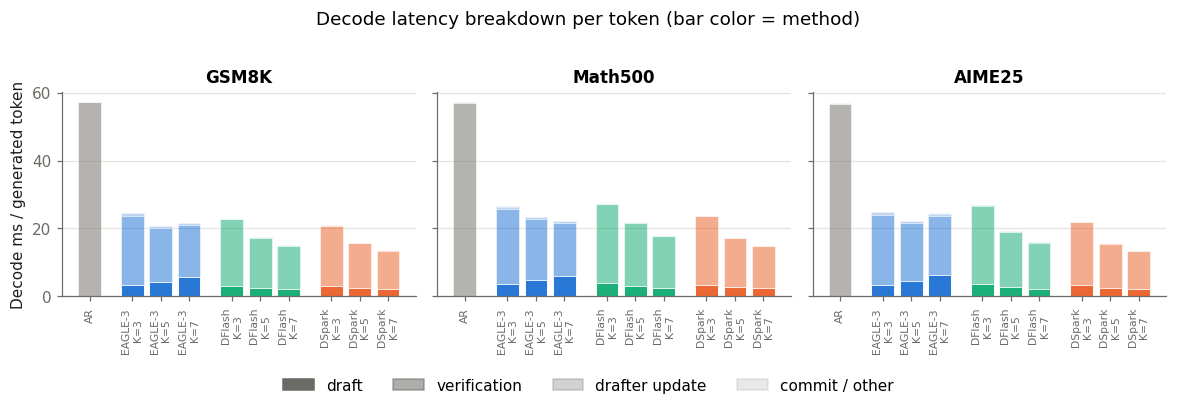

In [13]:
if STEP_TIMING:
    fig, axes = plt.subplots(1, len(DS), figsize=(3.6 * len(DS), 3.4), sharey=True, squeeze=False)
    shades = {"draft_ms": 1.0, "verification_ms": 0.55, "update_ms": 0.3, "commit_ms": 0.15}
    for ax, d in zip(axes[0], DS):
        ticks, labels, x = [], [], 0.0
        for m in ([AR_METHOD] if HAS_AR else []) + MS:
            for k in ([0] if m == AR_METHOD else KS):
                bottom = 0
                for p in PHASES:
                    v = metric(m, d, k, p + "_per_token")
                    v = 0 if not np.isfinite(v) else v
                    ax.bar(x, v, 0.8, bottom=bottom, color=STYLE[m]["color"], alpha=shades[p],
                           edgecolor="white", linewidth=0.6)
                    bottom += v
                ticks.append(x)
                labels.append("AR" if m == AR_METHOD else f"{name(m)}\nK={k}")
                x += 1
            x += 0.5  # gap between methods
        ax.set_xticks(ticks, labels, rotation=90, fontsize=7)
        ax.set_title(dname(d))
        ax.grid(axis="x", visible=False)
    axes[0, 0].set_ylabel("Decode ms / generated token")
    handles = [plt.Rectangle((0, 0), 1, 1, color=MUTED, alpha=a, label=PHASE_NAMES[p]) for p, a in shades.items()]
    fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
    fig.suptitle("Decode latency breakdown per token (bar color = method)", y=1.02)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    save(fig, "diag_latency_breakdown")
    plt.show()

    D2 = DIAG.set_index(["dataset", "method", "k"]).sort_index()[
        [p + "_per_round" for p in PHASES] + ["ms_per_round", "ms_per_token", "tokens_per_s", "speedup"]]
    D2.columns = [f"{PHASE_NAMES[p]} ms/round" for p in PHASES] + ["ms/round", "ms/token", "tokens/s", "speedup"]
    display(D2.style.format("{:.2f}", na_rep="—"))
    save_table(D2, "diag_latency")

### 11.3 Prefill, drafter initialisation, lengths and memory

Mean per sample. Prefill and `init_context` are excluded from all decode metrics above; they are reported here so
that the excluded cost is visible. `length-limited` = share of samples that hit `max_new_tokens`.

In [14]:
D3 = DIAG.set_index(["dataset", "method", "k"]).sort_index()[
    ["prefill_ms", "init_context_ms", "prompt_len", "generated_len", "length_limited", "steps", "peak_gib", "peak_max_gib"]
].rename(columns={"prefill_ms": "target prefill ms", "init_context_ms": "init_context ms", "prompt_len": "prompt len",
                  "generated_len": "generated len", "length_limited": "length-limited", "steps": "rounds",
                  "peak_gib": "peak GiB (mean)", "peak_max_gib": "peak GiB (max)"})
display(D3.style.format({"target prefill ms": "{:.1f}", "init_context ms": "{:.2f}", "prompt len": "{:.0f}",
                         "generated len": "{:.0f}", "length-limited": "{:.0%}", "peak GiB (mean)": "{:.2f}",
                         "peak GiB (max)": "{:.2f}"}, na_rep="—"))
save_table(D3, "diag_prefill_lengths_memory")

if len(workers):
    W = workers.groupby("method").agg(draft_params=("draft_params", "max"),
                                      post_load_gib=("post_load_allocated_bytes", lambda x: x.max() / GIB))
    W = W.reindex([m for m in [AR_METHOD] + MS if m in W.index])
    W["drafter params (M)"] = W.pop("draft_params") / 1e6
    W.index = W.index.map(name)
    display(Markdown("Drafter size (all drafter parameters, incl. its own embedding / LM head) and memory after loading:"))
    display(W.style.format({"post_load_gib": "{:.2f}", "drafter params (M)": "{:.0f}"}, na_rep="—"))

Drafter size (all drafter parameters, incl. its own embedding / LM head) and memory after loading:

,post_load_gib,drafter params (M)
method,,
AR (Qwen3-4B),7.55,—
EAGLE-3,9.27,927
DFlash,10.00,1315
DSpark,10.15,1393


### 11.4 Peak VRAM vs context length, and speedup vs additional VRAM

Left: per-sample peak allocated memory against final context length (prompt + generated) at `BASE_K`, with the AR
baseline. Right: decode speedup vs additional memory (Figure 3 definition), one point per (method, K), averaged over
datasets.

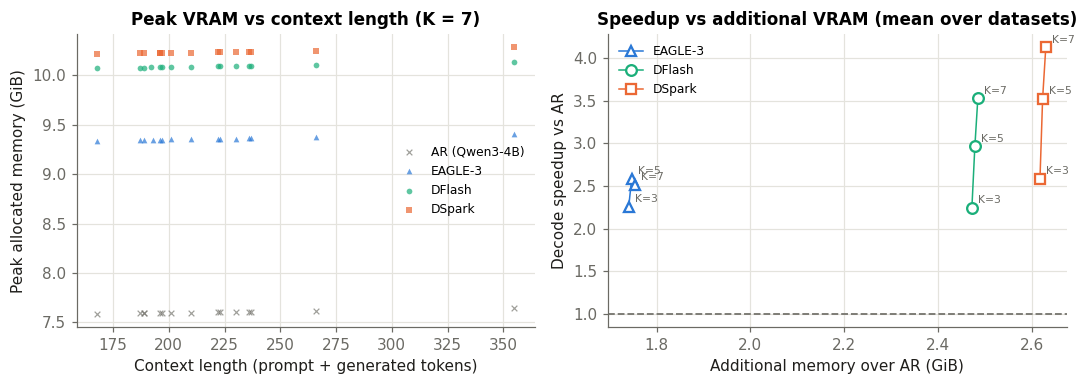

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
for m in ([AR_METHOD] if HAS_AR else []) + MS:
    sub = samples[(samples["method"] == m) & (samples["k"] == (0 if m == AR_METHOD else BASE_K))]
    if len(sub):
        ax.scatter(sub["context_len"], sub["peak_bytes"] / GIB, s=14, alpha=0.7, color=STYLE[m]["color"],
                   marker=STYLE[m]["marker"], label=name(m), linewidths=0.8 if STYLE[m]["marker"] == "x" else 0)
ax.set_xlabel("Context length (prompt + generated tokens)")
ax.set_ylabel("Peak allocated memory (GiB)")
ax.set_title(f"Peak VRAM vs context length (K = {BASE_K})")
ax.legend(fontsize=8)

ax = axes[1]
if len(MEM):
    sp = G[G["method"].isin(MS)].groupby(["method", "k"])["speedup"].mean()
    mm = MEM.groupby(["method", "k"])["total_gib"].mean()
    for m in MS:
        ks = [k for k in KS if (m, k) in sp.index and (m, k) in mm.index]
        ax.plot([mm[(m, k)] for k in ks], [sp[(m, k)] for k in ks], **STYLE[m], ls="-", lw=1,
                markerfacecolor="white", markeredgewidth=1.5, label=name(m))
        for k in ks:
            ax.annotate(f"K={k}", (mm[(m, k)], sp[(m, k)]), xytext=(4, 3), textcoords="offset points",
                        fontsize=7, color=MUTED)
    ax.axhline(1, color=AR_COLOR, ls="--", lw=1.2)
    ax.set_xlabel("Additional memory over AR (GiB)")
    ax.set_ylabel("Decode speedup vs AR")
    ax.set_title("Speedup vs additional VRAM (mean over datasets)")
    ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "diag_memory_context_speedup")
plt.show()

### 11.5 Conditional acceptance vs prefix survival, all K

Solid: conditional acceptance (Figure 1 definition). Dashed: DeepSpec's `accept_rates_by_position` (prefix survival
`P(accepted ≥ i | effective_len ≥ i)`), which is the product of the conditionals and therefore always decays. Rows =
datasets, columns = `K`; shows how running the block-7 checkpoints at other `K` changes per-position acceptance.

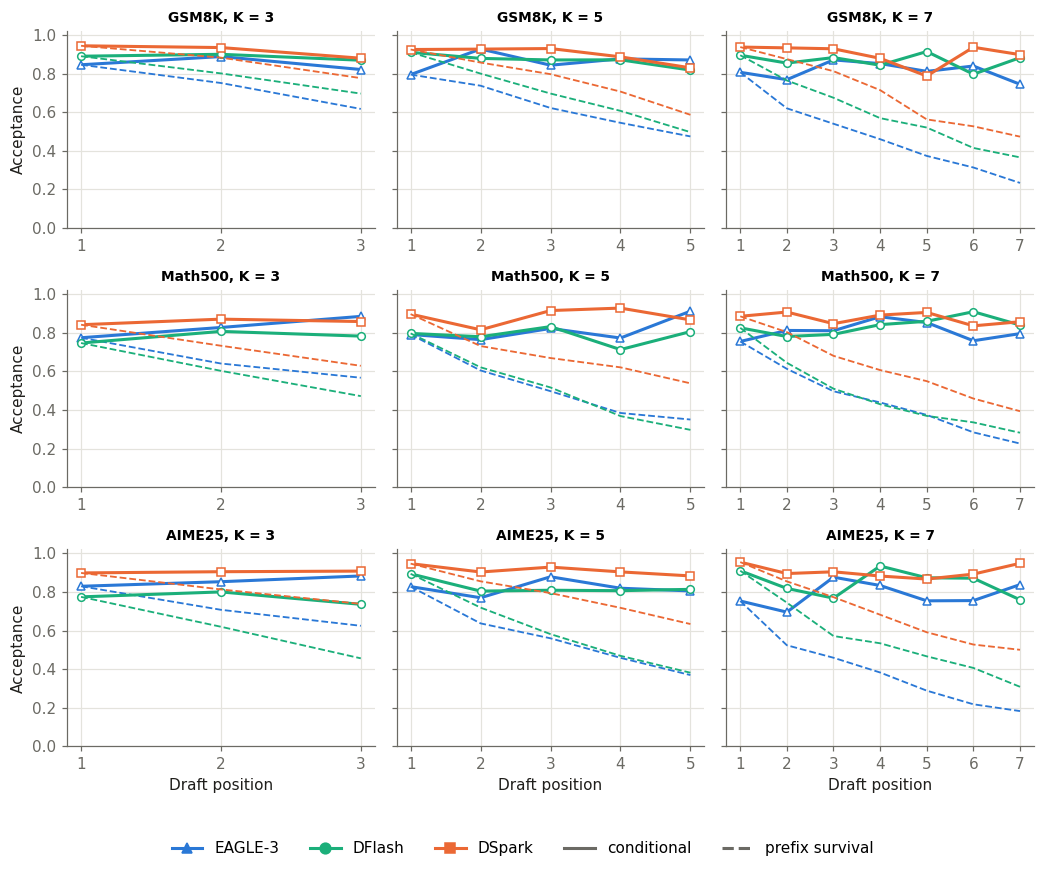

In [16]:
fig, axes = plt.subplots(len(DS), len(KS), figsize=(3.2 * len(KS), 2.6 * len(DS)), sharey=True, squeeze=False)
for i, d in enumerate(DS):
    for j, k in enumerate(KS):
        ax = axes[i, j]
        for m in MS:
            p = POS[(m, d, k)]
            ax.plot(p["position"], p["conditional"], **STYLE[m], markersize=5, markerfacecolor="white")
            ax.plot(p["position"], p["survival"], color=STYLE[m]["color"], ls="--", lw=1.2)
        ax.set_xticks(range(1, k + 1))
        ax.set_ylim(0, 1.02)
        ax.set_title(f"{dname(d)}, K = {k}", fontsize=9)
        if i == len(DS) - 1:
            ax.set_xlabel("Draft position")
    axes[i, 0].set_ylabel("Acceptance")
legend_below(fig, MS, extra=[plt.Line2D([], [], color=MUTED, ls="-", label="conditional"),
                              plt.Line2D([], [], color=MUTED, ls="--", label="prefix survival")])
fig.tight_layout(rect=(0, 0.05, 1, 1))
save(fig, "diag_position_acceptance_all_k")
plt.show()